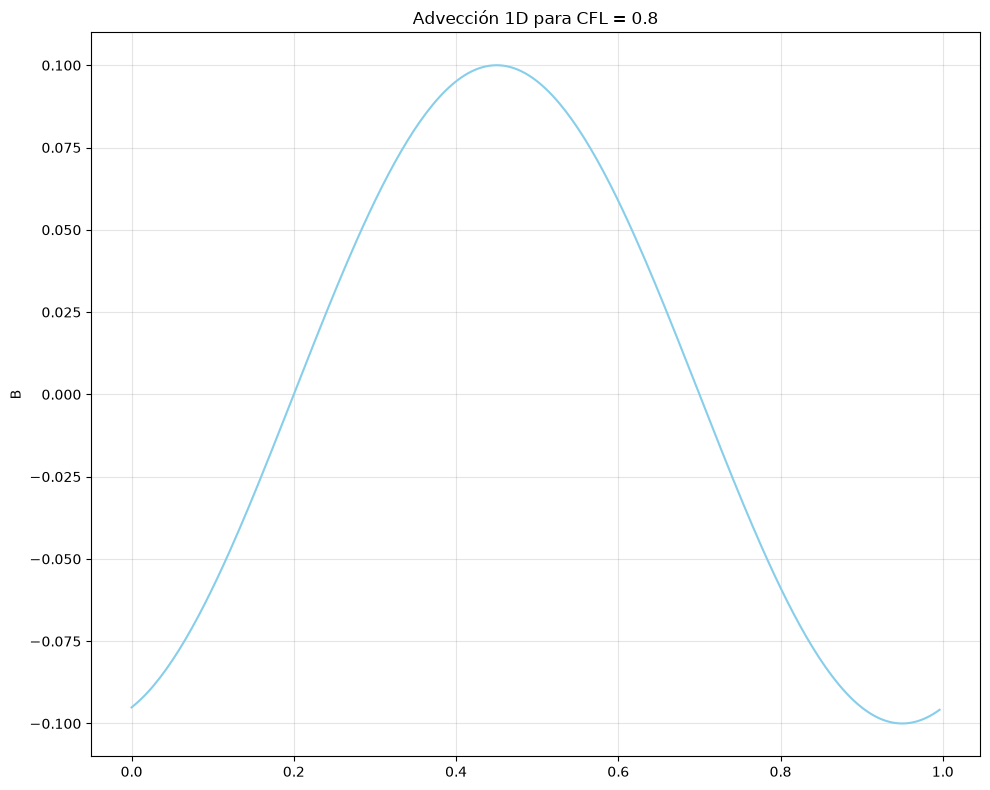

0.8


In [3]:
import numpy as np
import matplotlib.pyplot as plt

# OPCIÓN HLLD
N, L, A = 256, 1.0, 0.1
B0 = rho0 = mu0 = 1.0
vA = B0 / np.sqrt(mu0 * rho0)
dx = L / N
CFL = 0.8
dt = CFL * dx / vA

# Malla y condición inicial
x = np.linspace(0, L, N, endpoint=False)
dv0 = A * np.sin(2*np.pi*x / L)
dB0 = A * np.sin(2*np.pi*x / L)

# Bucle temporal
def advection1D_hlld(dv, dB):
    for _ in range(N):
        # Paso intermedio
        dv_half = 0.5 * (dv + np.roll(dv, -1)) + (dt/(2*dx)) * (B0/(mu0*rho0)) * (np.roll(dB, -1) - dB)
        dB_half = 0.5 * (dB + np.roll(dB, -1)) + (dt/(2*dx)) * (B0) * (np.roll(dv, -1) - dv)

        # Paso completo
        dv = dv + (dt/dx) * (B0/(mu0*rho0)) * (dB_half - np.roll(dB_half, 1))
        dB = dB + (dt/dx) * (B0) * (dv_half - np.roll(dv_half, 1))
    return dv, dB

dv, dB_a = advection1D_hlld(dv0, dB0)

fig, (ax1) = plt.subplots(1, 1, figsize=(10,8), sharex=True)

ax1.plot(x, dB_a, color='skyblue')
ax1.grid(color='gray', alpha=0.2)
ax1.set(ylabel='B', title=f'Advección 1D para CFL = {CFL}')

plt.tight_layout()
plt.show()

print(dt*256)

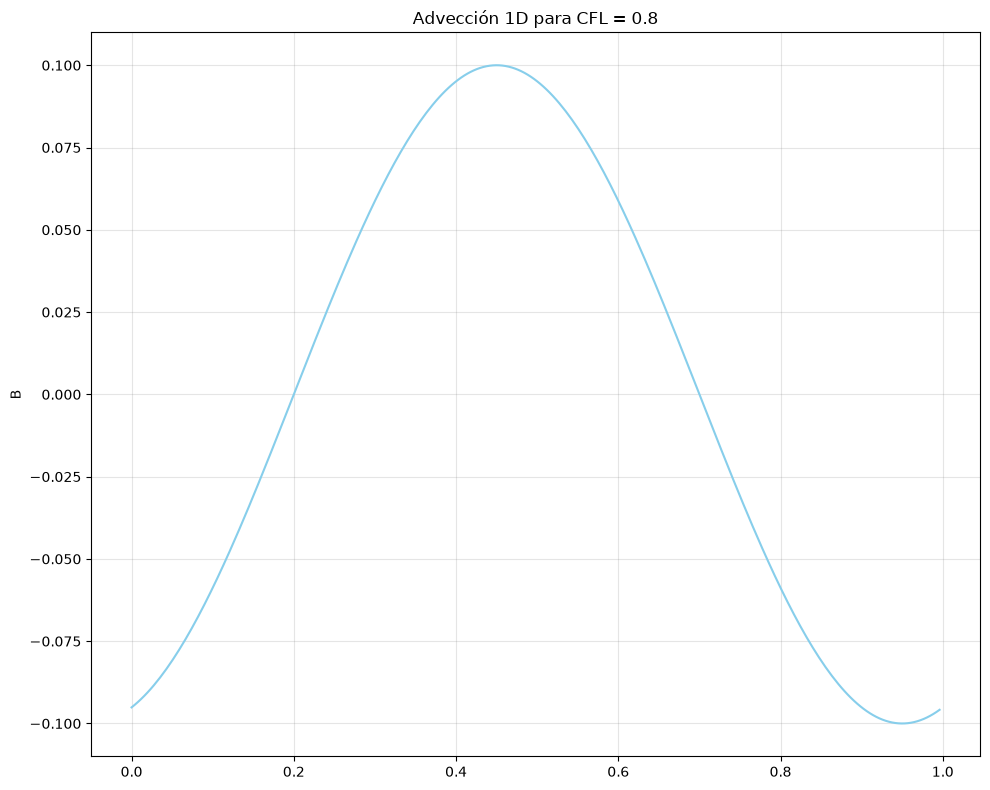

: 

In [ ]:
# Derivadas centradas espaciales:
def ddx(f, dx):
    return (np.roll(f, -1) - np.roll(f, 1)) / (2*dx)

# Tendencias:
def rhs(dv, dB, B0, rho0, dx):
    c     = B0 / (mu0 * rho0)
    dv_dt  = c * ddx(dB, dx)
    dB_dt = B0 * ddx(dv, dx)
    return dv_dt, dB_dt

# Bucle temporal:
def advection1D_rk2(dv, dB):
    for _ in range(N):
        # Etapa 1:
        dv1, dB1 = rhs(dv, dB, B0, rho0, dx)
        dv_star  = dv + dt * dv1
        dB_star  = dB + dt * dB1
        
        # Etapa 2:
        dv2, dB2 = rhs(dv_star, dB_star, B0, rho0, dx)
        dv = dv + 0.5*dt*(dv1 + dv2)
        dB = dB + 0.5*dt*(dB1 + dB2)
    return dv, dB

dv, dB_b = advection1D_rk2(dv0, dB0)

fig, (ax1) = plt.subplots(1, 1, figsize=(10,8), sharex=True)

ax1.plot(x, dB_b, color='skyblue')
ax1.grid(color='gray', alpha=0.2)
ax1.set(ylabel='B', title=f'Advección 1D para CFL = {CFL}')

plt.tight_layout()
plt.show()